Components provide the state representations and operations that a model
combines. In CMR, item-to-context memory cues a context representation,
context-to-item memory supports retrieval, and a termination policy supplies
a stopping probability. The model determines when and how to use them.

## Context, memory and termination interfaces

`Context` stores the current and initial context and returns updated context
after integration. Its full interface also includes integration with new
out-of-list input.

Selected declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class Context(Protocol):
    state: Float[Array, " context_feature_units"]
    initial_state: Float[Array, " context_feature_units"]
    size: int

    def integrate(
        self,
        context_input: Float[Array, " context_feature_units"],
        drift_rate: Float_,
    ) -> "Context": ...
```

`Memory` maps input patterns to output patterns through `probe()`, and returns
updated associative state through `associate()`. Its full interface also
exposes input and output sizes.

Selected declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class Memory(Protocol):
    state: Float[Array, " input_size output_size"]

    def associate(
        self,
        in_pattern: Float[Array, " input_size"],
        out_pattern: Float[Array, " output_size"],
        learning_rate: Float_,
    ) -> "Memory": ...

    def probe(
        self, in_pattern: Float[Array, " input_size"]
    ) -> Float[Array, " output_size"]: ...
```

A termination policy consumes a compatible model or model view and returns
a scalar stopping probability. `ModelT` records the kind of object that a
particular policy needs; policies need not accept every memory-search model.

Declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class TerminationPolicy[ModelT](Protocol):
    def stop_probability(self, model: ModelT) -> Float[Array, ""]: ...
```

These protocols describe extension points for compatible implementations.
They do not prescribe a context equation, association rule or stopping rule,
and do not require inheritance from a common implementation class.

## Creators supply components to a model

Models need fresh components with compatible dimensions and parameters.
Creator functions provide these objects when a model is constructed.

Declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class ContextCreateFn(Protocol):
    def __call__(self, item_count: int) -> Context: ...
```

Declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class MemoryCreateFn(Protocol):
    def __call__(
        self,
        list_length: int,
        parameters: Mapping[str, Float_],
        context: Context,
    ) -> Memory: ...
```

Declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class TerminationPolicyCreateFn[ModelT](Protocol):
    def __call__(
        self, list_length: int, parameters: Mapping[str, Float_]
    ) -> TerminationPolicy[ModelT]: ...
```

Ordinary CMR's `make_factory()` accepts four such callables:

| Factory argument | Existing implementation used here | Role |
|---|---|---|
| `context_create_fn` | `context.init` | Construct temporal context. |
| `mfc_create_fn` | `linear_memory.init_mfc` | Construct item-to-context memory. |
| `mcf_create_fn` | `linear_memory.init_mcf` | Construct context-to-item memory. |
| `termination_policy_create_fn` | `NoStopTermination` | Construct the stopping policy. |

A compatible function or callable class can occupy one of these arguments.
Each memory creator returns one memory with the appropriate direction and
dimensions. Changing a creator changes that component's implementation;
the model still owns its event ordering, parameter interpretation and
composition rules. Other models may expose different configuration choices.

In [ ]:
#| code-summary: "0 — Locate the project inputs"

from pathlib import Path

from jaxcmr.helpers import find_project_root, resolve_project_path

try:
    root_path = Path(find_project_root())
except FileNotFoundError:
    root_path = Path.cwd()


In [1]:
#| code-summary: "Connect the component creators and inspect the resulting objects"

from pathlib import Path
import json
import jax
import jax.numpy as jnp
from jaxcmr.helpers import load_data, generate_trial_mask
from jaxcmr.components import context, linear_memory
from jaxcmr.components.termination import NoStopTermination
from jaxcmr.models.cmr import make_factory

jax.config.update("jax_enable_x64", True)
data = load_data(resolve_project_path("data/Dupertuys2026.h5", root_path))
record = json.loads(Path(resolve_project_path("data/fits/Dupertuys2026_CMR_demo.json", root_path)).read_text())
parameters = {name: values[0] for name, values in record["fits"].items()
              if name != "subject"}
for name in ("allow_repeated_recalls", "learn_after_context_update"):
    parameters[name] = bool(parameters[name])

CMRFactory = make_factory(
    mfc_create_fn=linear_memory.init_mfc,
    mcf_create_fn=linear_memory.init_mcf,
    context_create_fn=context.init,
    termination_policy_create_fn=NoStopTermination,
)

factory = CMRFactory(data, features=None)
mixed = generate_trial_mask(data, "data['list_type'] == 1")
trial_index = int(jnp.flatnonzero(mixed)[0])
initial = factory.create_trial_model(trial_index, parameters)
print("Context:", type(initial.context).__name__, initial.context.state.shape)
print("Item-to-context memory:", type(initial.mfc).__name__, initial.mfc.state.shape)
print("Context-to-item memory:", type(initial.mcf).__name__, initial.mcf.state.shape)
print("Termination:", type(initial.termination_policy).__name__)

Context: TemporalContext (13,)
Item-to-context memory: LinearMemory (12, 13)
Context-to-item memory: LinearMemory (13, 12)
Termination: NoStopTermination


## What the model does with them

For a CMR study event, item-to-context memory is probed with the item pattern.
Context integrates that input using encoding drift. The model then updates
both associative memories; `learn_after_context_update` determines which
context state is used for learning. During retrieval, context-to-item memory
supplies item activations and the termination policy supplies stopping
support. Those steps belong to CMR's composition, not to `Context` or `Memory`
on their own.

Original study count: 0
Updated study count: 1
Context changed: True


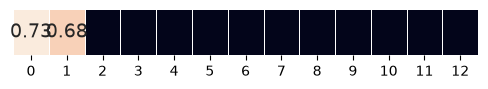

In [2]:
#| code-summary: "Display the context after CMR processes one study event"

from IPython.display import display

updated = initial.experience(data["pres_itemnos"][trial_index, 0])
print("Original study count:", int(initial.study_index))
print("Updated study count:", int(updated.study_index))
print("Context changed:", not bool(jnp.allclose(
    initial.context.state, updated.context.state
)))
display(updated.context)

The figure uses the context object's built-in notebook display. It shows the
representation after one update; the original model retains its earlier
state. A compatible replacement must satisfy the required dimensions,
functional update behavior and JAX operations, as well as the protocol's
named methods. A termination policy additionally needs the attributes of
the model or view passed to it.

See [Memory Search Models](models.ipynb) for the enclosing lifecycle and the
[parameter exploration template](../templates/parameter_shifting.ipynb) for
changing parameters within a fixed model configuration.